# Maternal BMI: prediction intervals under a misspecified distribution

A 90% prediction interval should contain about 90% of new responses from the
population it is intended to cover. This study compares intervals for maternal
BMI when the fitted response distribution is misspecified.

The usual approach is to fit a model, rely on its distributional assumption,
and derive the interval from it. This study asks what to do when that
assumption is wrong.

This case teaches how to separate a useful mean model from a calibrated prediction
interval. It compares distributional intervals with conformal intervals when the
checked distributional fits show diagnostic departures.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | whether an interval labelled 90% covers about 90% of future observations |
| **Observed response** | `mbmi`, maternal BMI |
| **Estimand** | the conditional quantiles of the response, which is what an interval claims to bracket |
| **Units** | BMI, kg/m² |
| **Sampling unit** | one mother |
| **Dependence** | treated as independent |
| **Split / resampling unit** | the mother; the conformal calibration split holds out whole rows |
| **Tuning** | `mstop` by cross-validated risk |
| **Uncertainty** | conformal calibration, and coverage measured against the held-out fraction |
| **Claim type** | predictive, and the study's subject is exactly whether the predictive claim holds |
:::


## The data

The India sample records mothers and their children. Here we predict the
mother's BMI from her age and her child's age and BMI.

We assess predictions by held-out interval coverage. The fitted associations
do not estimate effects of changing a mother's or child's measurements.

BMI is positive and strongly right-skewed. A few observations lie far above
the bulk of the distribution, and none are negative. The skewness is the main
feature of the response.

In [1]:
import warnings

import numpy as np
import polars as pl

import mboostrs as mb

warnings.filterwarnings("ignore", message="Some 'x' values are beyond")

data = mb.datasets.india(output="records")
n = len(data["mbmi"])
bmi = np.asarray(data["mbmi"])
standardised = (bmi - bmi.mean()) / bmi.std(ddof=1)
print(f"n = {n}")
print(f"mother's BMI: mean {bmi.mean():.1f}, median {np.median(bmi):.1f}, "
      f"range {bmi.min():.1f} to {bmi.max():.1f}")
print(f"skewness {float((standardised ** 3).mean()):+.2f} "
      f"(0 for a symmetric distribution)")

n = 4000
mother's BMI: mean 19.8, median 19.4, range 13.1 to 39.8
skewness +1.32 (0 for a symmetric distribution)


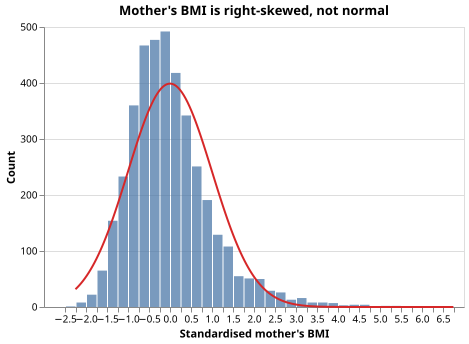

In [2]:
import altair as alt

bw = 0.25
hist = alt.Chart(pl.DataFrame({"z": standardised})).mark_bar(opacity=0.75).encode(
    x=alt.X("z:Q", bin=alt.Bin(step=bw), title="Standardised mother's BMI"),
    y=alt.Y("count():Q", title="Count"),
)
xs = np.linspace(standardised.min(), standardised.max(), 200)
normal = pl.DataFrame({
    "x": xs,
    "count": np.exp(-0.5 * xs ** 2) / np.sqrt(2 * np.pi) * n * bw,
})
ref = alt.Chart(normal).mark_line(color="#d62728", strokeWidth=2).encode(
    x=alt.X("x:Q", title="Standardised mother's BMI"),
    y=alt.Y("count:Q", title="Count"),
)
(hist + ref).properties(
    title="Mother's BMI is right-skewed, not normal", width=420, height=280)

The histogram shows the skew directly. Most mothers are near the median of 19.4,
and the tail extends to 39.8. The skewness is +1.32. A normal distribution
with the same mean and variance places mass below zero, which the data cannot
have.

In [3]:
rng = np.random.default_rng(3)
order = rng.permutation(n)
train = {k: np.asarray(v)[order[:3000]] for k, v in data.items()}
test = {k: np.asarray(v)[order[3000:]] for k, v in data.items()}
observed = np.asarray(test["mbmi"])
terms = "bbs(mage, df=4) + bbs(cage, df=4) + bbs(cbmi, df=4)"


def report(label, lower, upper):
    return {
        "interval": label,
        "coverage": f"{np.mean((observed >= lower) & (observed <= upper)) * 100:.1f}%",
        "misses low": f"{np.mean(observed < lower) * 100:.1f}%",
        "misses high": f"{np.mean(observed > upper) * 100:.1f}%",
        "mean width": round(float(np.mean(upper - lower)), 2),
    }

## Gaussian prediction interval

The first model is a Gaussian additive model. The interval is formed from the
fitted value plus or minus 1.645 residual standard deviations. This is the
default workflow in a standard regression pipeline.

The interval should be checked against held-out data, and both tails should be
checked separately. A 90% interval makes two promises: about 5% of
observations should fall below it and about 5% above it.

In [4]:
gaussian = mb.gamboost(f"mbmi ~ {terms}", data=train, family=mb.Gaussian(),
                       control=mb.boost_control(300, 0.1))
centre = np.asarray(gaussian.predict(newdata=test))
residual_sd = float(np.std(np.asarray(train["mbmi"])
                           - np.asarray(gaussian.fitted_), ddof=1))

rows = [report("Gaussian, model-based",
               centre - 1.645 * residual_sd, centre + 1.645 * residual_sd)]
display(pl.DataFrame(rows))

interval,coverage,misses low,misses high,mean width
str,str,str,str,f64
"""Gaussian, model-based""","""92.8%""","""1.5%""","""5.7%""",9.59


Overall coverage is 92.8%, above the nominal 90%.

The tails tell a different story. Only 1.5% of observations fall below the
interval and 5.7% above it, whereas both should be about 5%. The interval is
too wide in the lower tail and too narrow in the upper tail. The aggregate
coverage is high because the two errors partly cancel.

A single coverage number can hide two offsetting errors. The problem appears
in the two tails rather than in different subgroups, but the aggregate number
still conceals it.

### Fitted effects

The tail errors assess the predictive distribution. We also inspect fitted
effects and residuals for patterns that would suggest a misspecified mean.

In [5]:
mb.plot.plot_partial_effects(gaussian).properties(
    title="Fitted effects, Gaussian model")

Each effect is smooth and of a plausible size, and the residuals show no
pattern against the fitted values. The conditional mean is estimated
reasonably.

The fitted mean is reasonable, but these diagnostics do not assess the
residual distribution. A residual plot against fitted values checks whether
residuals vary around zero; it does not compare their distribution with
the Gaussian assumption used to form the interval.

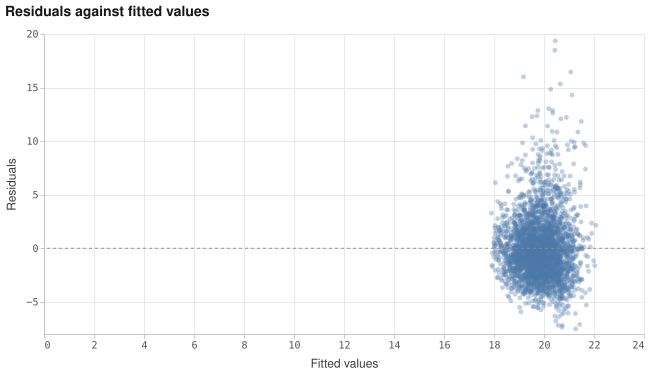

In [6]:
mb.plot.plot_residuals(gaussian).properties(
    title="Residuals against fitted values")

## Family scan: `scan_lss_families`

The response is positive and right-skewed. Gamma is a natural candidate, but
the fitted models are ranked by out-of-bag risk rather than assumed to help.

In [7]:
specification = {"mu": f"mbmi ~ {terms}", "sigma": f"mbmi ~ {terms}"}
ranking = mb.scan_lss_families(
    specification, data=data,
    families=["GaussianLSS", "LogisticLSS", "GammaLSS",
              "InverseGaussianLSS", "BCCGLSS"],
    metric="cvrisk", fit_func="gamboostLSS",
    control=mb.boost_control(200, 0.1),
)
display(pl.DataFrame([
    {"family": r["family"], "out-of-bag risk": round(r["cvrisk"], 4)}
    for r in ranking if r["status"] == "ok"
]))

/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamlss.py:4320: RuntimeWarning: the lowest cross-validated risk is at [200, 200], the largest budget in the grid, so the reported optimum is where the search stopped rather than where the risk turns. Extend the grid -- mb.diagonal_grid(400, 2) -- and refit with a control whose mstop covers it.
  return entry(folds=folds if isinstance(folds, FoldScheme) else folds_matrix,


family,out-of-bag risk
str,f64
"""LogisticLSS""",2.4261
"""GaussianLSS""",2.4647
"""InverseGaussianLSS""",2.567
"""BCCGLSS""",2.5887
"""GammaLSS""",2.6329


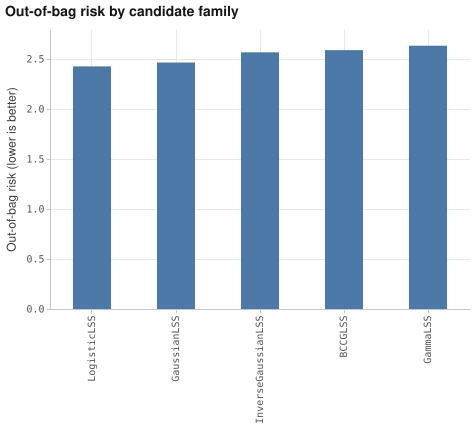

In [8]:
import altair as alt

ranking_frame = pl.DataFrame([
    {"family": r["family"], "out-of-bag risk": round(r["cvrisk"], 4)}
    for r in ranking if r["status"] == "ok"
])
alt.Chart(ranking_frame).mark_bar(size=38).encode(
    x=alt.X("family:N", title=None, sort=None),
    y=alt.Y("out-of-bag risk:Q", title="Out-of-bag risk (lower is better)"),
    tooltip=[alt.Tooltip("family:N", title="Family"),
             alt.Tooltip("out-of-bag risk:Q", format=".4f",
                         title="Out-of-bag risk")],
).properties(title="Out-of-bag risk by candidate family", width=420, height=280)

LogisticLSS ranks first, with an out-of-bag risk of 2.43. GaussianLSS ranks
second at 2.46 and GammaLSS last at 2.63. Replacing the Gaussian family with
a Gamma family does not improve the fit.

The ranking compares out-of-bag risk among the fitted families. A probability
integral transform (PIT) diagnostic then compares each fitted distribution
with the observed responses.

## PIT check of the candidate families

For independent observations evaluated under their true conditional CDF,
PIT values are uniform on (0, 1). A chi-square statistic against ten uniform
bins has a 5% critical value of 16.9 on 9 degrees of freedom when the values
are independent and uniform. Here the distributions are estimated on the
same rows used for the PIT, so that reference is descriptive rather than a
calibrated 5% test of the fitted families.


In [9]:
uniformity = []
for name in ("GaussianLSS", "GammaLSS", "BCCGLSS"):
    spec = dict(specification)
    if name == "BCCGLSS":
        spec["nu"] = f"mbmi ~ {terms}"
    fit = mb.gamboostLSS(spec, data=data, families=getattr(mb, name)(),
                         control=mb.boost_control(200, 0.1))
    values = np.asarray(fit.pit(random_state=0))
    observed_bins, _ = np.histogram(values, bins=10, range=(0, 1))
    uniformity.append({
        "family": name,
        "PIT chi-square": round(float(((observed_bins - n / 10) ** 2
                                       / (n / 10)).sum()), 1),
    })
display(pl.DataFrame(uniformity))
print("5% critical value on 9 df: 16.9")

family,PIT chi-square
str,f64
"""GaussianLSS""",205.3
"""GammaLSS""",4129.8
"""BCCGLSS""",2803.1


5% critical value on 9 df: 16.9


All three checked fits have PIT chi-square statistics well above the 16.9
reference. GaussianLSS has the smallest statistic at 205.3; GammaLSS scores
4129.8 and BCCGLSS 2803.1. These in-sample histograms show departures from
uniformity under the fitted specifications and stopping budgets. They do not
establish that every family in the catalogue fails to describe this response.

The diagnostic does not isolate the source of the departures. Assessing
predictive calibration requires observations held out from fitting; attributing
the discrepancy to response-family choice would also require checking the
predictor specifications and fitting budgets.


## Gamma prediction interval

The scan and the PIT suggest that Gamma will not help. Fitting it anyway
quantifies the cost of that choice.

In [10]:
gamma_fit = mb.gamboostLSS(specification, data=train, families=mb.GammaLSS(),
                           control=mb.boost_control(300, 0.1))
gamma_interval = gamma_fit.prediction_interval(newdata=test, level=0.90)
rows.append(report("GammaLSS, model-based",
                   np.asarray(gamma_interval["lower"]),
                   np.asarray(gamma_interval["upper"])))
display(pl.DataFrame(rows))

interval,coverage,misses low,misses high,mean width
str,str,str,str,f64
"""Gaussian, model-based""","""92.8%""","""1.5%""","""5.7%""",9.59
"""GammaLSS, model-based""","""94.8%""","""5.1%""","""0.1%""",17.32


The Gamma interval covers 94.8%, further from nominal than the Gaussian 92.8%,
and it is nearly twice as wide: 17.3 versus 9.6. It misses high values 0.1% of
the time and low values 5.1% of the time. It replaces one asymmetry with the
opposite one while giving up most of its precision.

The scan and the PIT already point to the same conclusion. The Gamma family is
a standard choice for a right-skewed positive response, but it performs worse
here.

## Conformal intervals

Split conformal and conformalized quantile regression (CQR) calibrate intervals
using prediction errors on held-out rows. They provide marginal coverage when
rows are exchangeable, fitting is symmetric, and the specification was fixed
without calibration responses. Their validity does not require the fitted
response family or noise distribution to be correct.

The model is unchanged. The same misspecified Gaussian fit is used.

In [11]:
for method in ("split", "cv+", "cqr"):
    interval = mb.conformal_interval(gaussian, newdata=test, level=0.9,
                                     method=method, seed=1)
    rows.append(report(f"conformal ({method}), same model",
                       np.asarray(interval.lower), np.asarray(interval.upper)))
display(pl.DataFrame(rows))

/Users/fcela/.local/share/uv/python/cpython-3.12.11-macos-aarch64-none/lib/python3.12/contextlib.py:144: ExtrapolationWarning: 1 fold prediction in this call asked 1 learner(s) to predict outside the range they were fitted on. bbs(mage), covariate mage: 2 above 47 (worst 0.059 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.059 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  next(self.gen)
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 300 is within 5% of the search cap 300; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: o

/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 1200 is within 5% of the search cap 1200; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


interval,coverage,misses low,misses high,mean width
str,str,str,str,f64
"""Gaussian, model-based""","""92.8%""","""1.5%""","""5.7%""",9.59
"""GammaLSS, model-based""","""94.8%""","""5.1%""","""0.1%""",17.32
"""conformal (split), same model""","""89.8%""","""3.4%""","""6.8%""",8.65
"""conformal (cv+), same model""","""89.6%""","""3.6%""","""6.8%""",8.66
"""conformal (cqr), same model""","""90.0%""","""5.1%""","""4.9%""",8.95


Coverage is within a point of nominal for all three methods: 89.8% for split,
89.6% for cv+, and 90.9% for cqr. The intervals are also narrower than the
Gaussian intervals they replace, about 8.7 wide versus 9.6. These are empirical
fresh-sample results. CV+ has a finite-sample lower bound below its nominal
level; each result records its bound and assumptions.

Conformal fixes the overall coverage but leaves the asymmetry: split conformal
is 3.4% low and 6.8% high, cv+ is 3.6% and 6.8%, and cqr is 2.5% and
6.6%. CQR uses one maximum nonconformity score for both tails; it does not
calibrate them separately. The miss pattern is inherited from the
misspecified model rather than corrected. Split conformal guarantees marginal
coverage and promises nothing about where the misses fall; conditional validity
would require the model to be right.

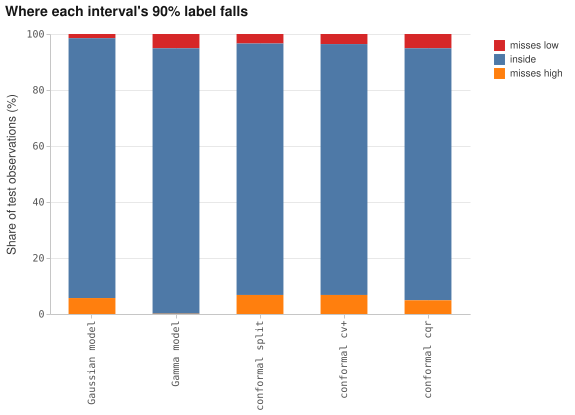

In [12]:
import altair as alt
# Plot the quantities interpreted in the following paragraph.
short = {"Gaussian, model-based": "Gaussian model",
         "GammaLSS, model-based": "Gamma model",
         "conformal (split), same model": "conformal split",
         "conformal (cv+), same model": "conformal cv+",
         "conformal (cqr), same model": "conformal cqr"}
parts = []
for row in rows:
    low = float(row["misses low"].rstrip("%"))
    high = float(row["misses high"].rstrip("%"))
    inside = float(row["coverage"].rstrip("%"))
    parts.append({"interval": short[row["interval"]], "part": "misses low",
                  "share": low})
    parts.append({"interval": short[row["interval"]], "part": "inside",
                  "share": inside})
    parts.append({"interval": short[row["interval"]], "part": "misses high",
                  "share": high})
composition = pl.DataFrame(parts)

alt.Chart(composition).mark_bar().encode(
    x=alt.X("interval:N", title=None, sort=None),
    y=alt.Y("share:Q", title="Share of test observations (%)"),
    color=alt.Color(
        "part:N", title=None,
        scale=alt.Scale(domain=["misses low", "inside", "misses high"],
                        range=["#d62728", "#4e79a7", "#ff7f0e"])),
    tooltip=[alt.Tooltip("interval:N", title="Interval"),
             alt.Tooltip("part:N", title="Where the observation falls"),
             alt.Tooltip("share:Q", format=".1f", title="Share (%)")],
).properties(title="Where each interval's 90% label falls", width=420, height=280)


## Summary

The Gaussian interval for this response is miscalibrated. The lower tail misses 1.5% of observations and the upper tail misses 5.7%, whereas both should be about 5%. Conformal intervals recover marginal coverage without changing the model. Across the three methods, coverage ranges from 89.6% to 90.9%, and the intervals are narrower than the Gaussian ones.

Conformal intervals do not provide conditional validity. They give about 90% marginal coverage, but the split between low and high misses shows that coverage is still unequal across the tails.

Gamma is a poor family for this response. The scan ranked Gamma last of five families, and its in-sample PIT histogram departs substantially from uniformity.

Response-family misspecification can affect point predictions, fitted-parameter interpretations and conditional coverage. Conformal calibration addresses marginal coverage; the tail-specific errors above remain relevant when high and low misses have different consequences.